# Rice (Cammeo vs Osmancik) - Exploratory Data Analysis

## 1. Setup and data

In [22]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")

TARGET = "Class"
OUT = Path("eda_graphs")
OUT.mkdir(exist_ok=True)

rice = pd.read_csv("Rice_Cammeo_Osmancik.csv")
FEATS = rice.columns.drop(TARGET).tolist()


def finish(name, dpi=150):
    """Tidy, save into eda_graphs/ and display the current figure."""
    plt.tight_layout()
    plt.savefig(OUT / f"{name}.png", dpi=dpi, bbox_inches="tight")
    plt.show()
    plt.close()


## 2. Overview

In [23]:
rice.head()

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,15231,525.578979,229.749878,85.093788,0.928882,15617,0.572896,Cammeo
1,14656,494.311005,206.020065,91.730972,0.895405,15072,0.615436,Cammeo
2,14634,501.122009,214.106781,87.768288,0.912118,14954,0.693259,Cammeo
3,13176,458.342987,193.337387,87.448395,0.891861,13368,0.640669,Cammeo
4,14688,507.166992,211.743378,89.312454,0.906691,15262,0.646024,Cammeo


In [24]:
rice.info()

<class 'pandas.DataFrame'>
RangeIndex: 3810 entries, 0 to 3809
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Area               3810 non-null   int64  
 1   Perimeter          3810 non-null   float64
 2   Major_Axis_Length  3810 non-null   float64
 3   Minor_Axis_Length  3810 non-null   float64
 4   Eccentricity       3810 non-null   float64
 5   Convex_Area        3810 non-null   int64  
 6   Extent             3810 non-null   float64
 7   Class              3810 non-null   str    
dtypes: float64(5), int64(2), str(1)
memory usage: 238.3 KB


In [25]:
summary = rice[FEATS].describe().T
summary["missing"] = rice[FEATS].isna().sum()
summary["skew"] = rice[FEATS].skew()
print("duplicate rows:", rice.duplicated().sum())
print(rice[TARGET].value_counts(), "\n")
summary.round(3)


duplicate rows: 0
Class
Osmancik    2180
Cammeo      1630
Name: count, dtype: int64 



,count,mean,std,min,25%,50%,75%,max,missing,skew
Area,3810.0,12667.728,1732.368,7551.000,11370.500,12421.500,13950.000,18913.000,0,0.325
Perimeter,3810.0,454.239,35.597,359.100,426.145,448.852,483.684,548.446,0,0.221
Major_Axis_Length,3810.0,188.776,17.449,145.264,174.354,185.810,203.550,239.010,0,0.260
Minor_Axis_Length,3810.0,86.314,5.730,59.532,82.732,86.435,90.144,107.542,0,-0.135
Eccentricity,3810.0,0.887,0.021,0.777,0.872,0.889,0.903,0.948,0,-0.449
Convex_Area,3810.0,12952.497,1776.972,7723.000,11626.250,12706.500,14284.000,19099.000,0,0.320
Extent,3810.0,0.662,0.077,0.497,0.599,0.645,0.727,0.861,0,0.344


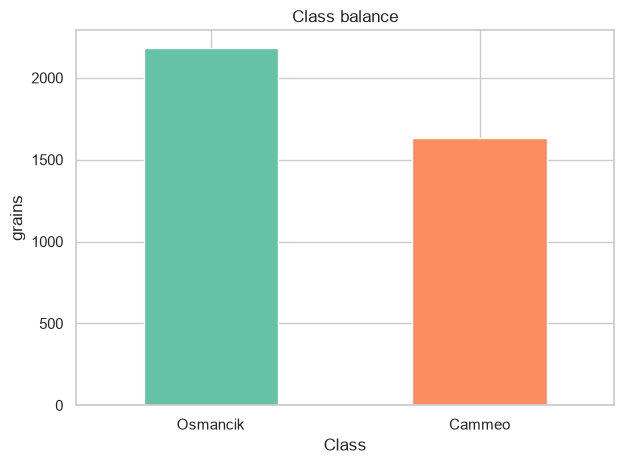

In [26]:
ax = rice[TARGET].value_counts().plot.bar(color=sns.color_palette("Set2")[:2], rot=0)
ax.set_title("Class balance")
ax.set_ylabel("grains")
finish("class_balance")


## 3. Scatter plots

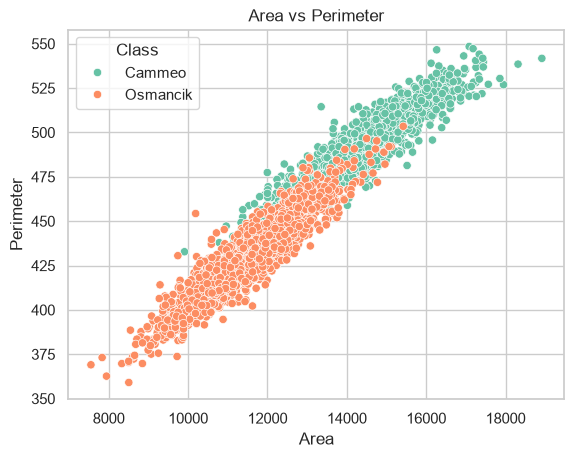

In [27]:
sns.scatterplot(data=rice, x="Area", y="Perimeter", hue=TARGET)
plt.title("Area vs Perimeter")
plt.show()


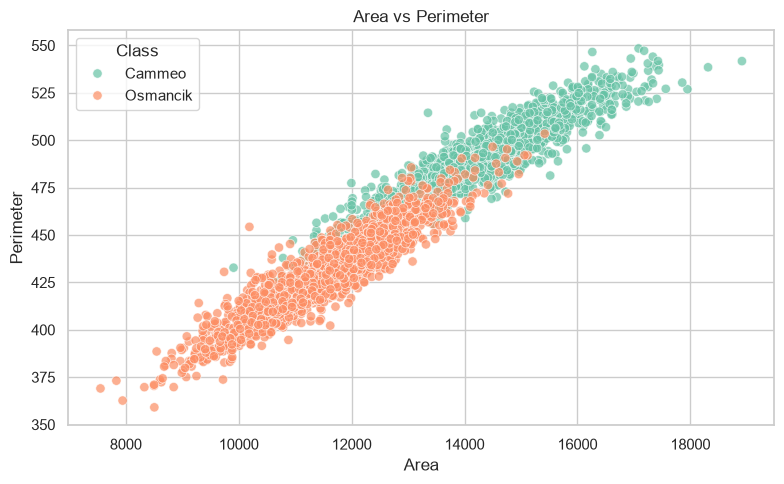

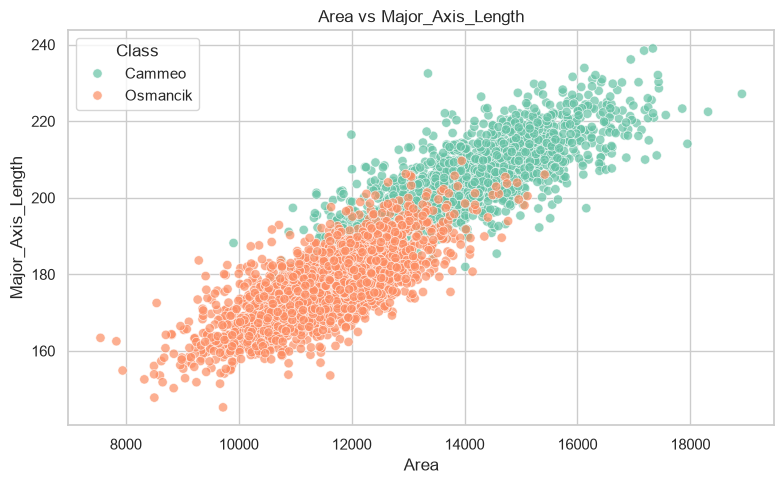

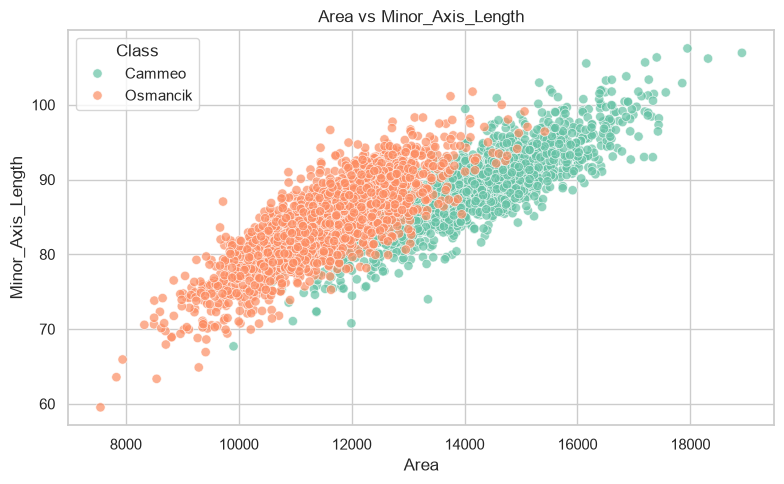

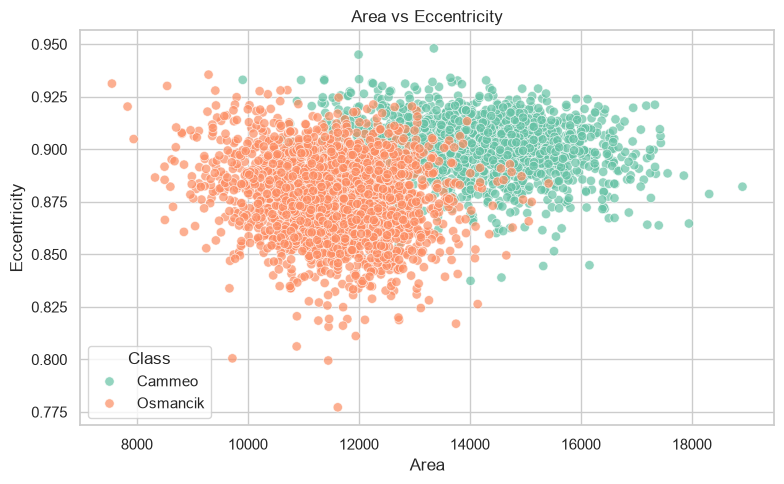

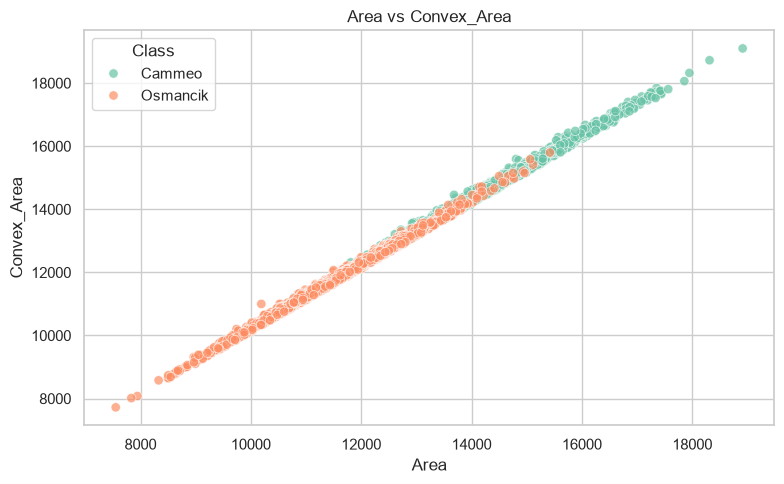

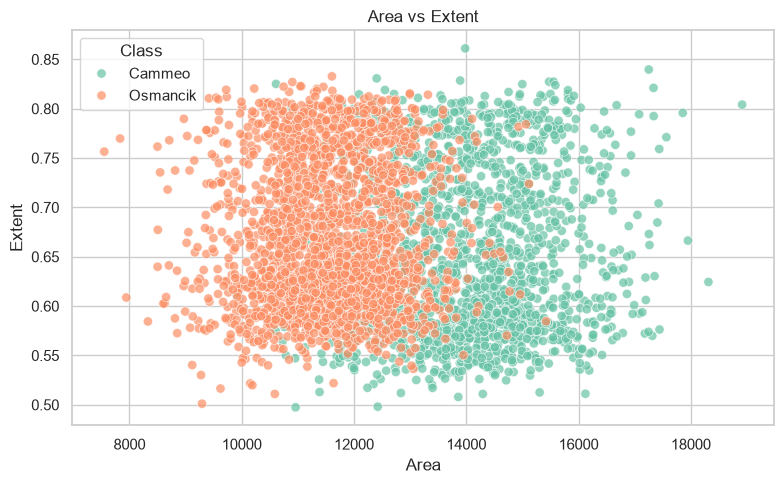

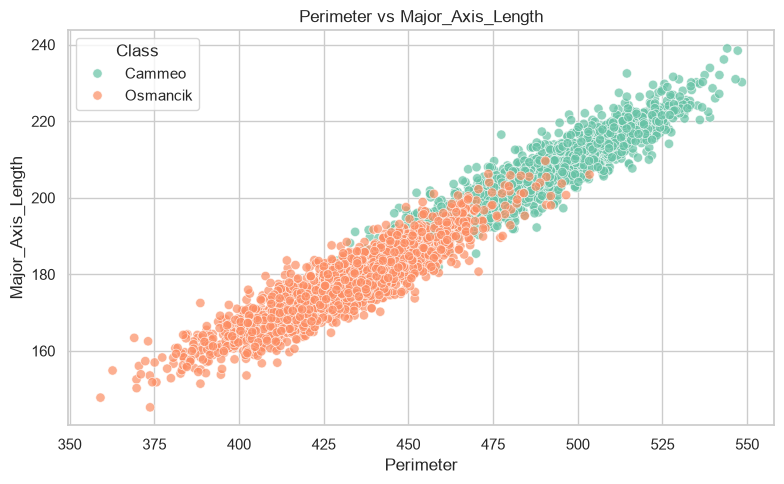

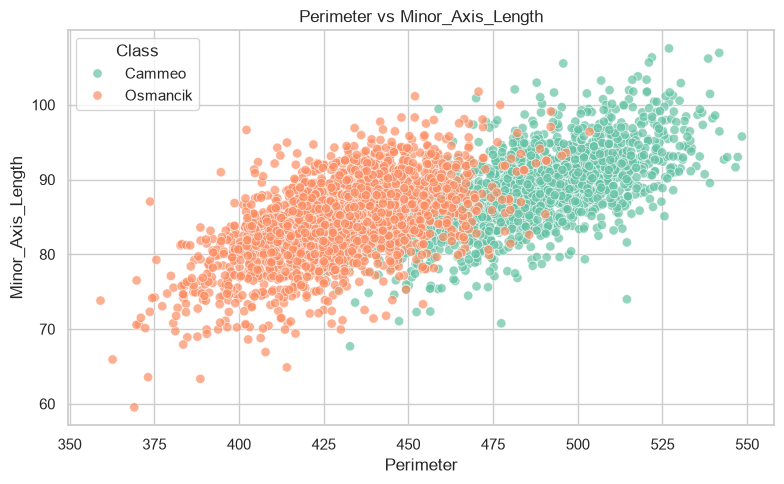

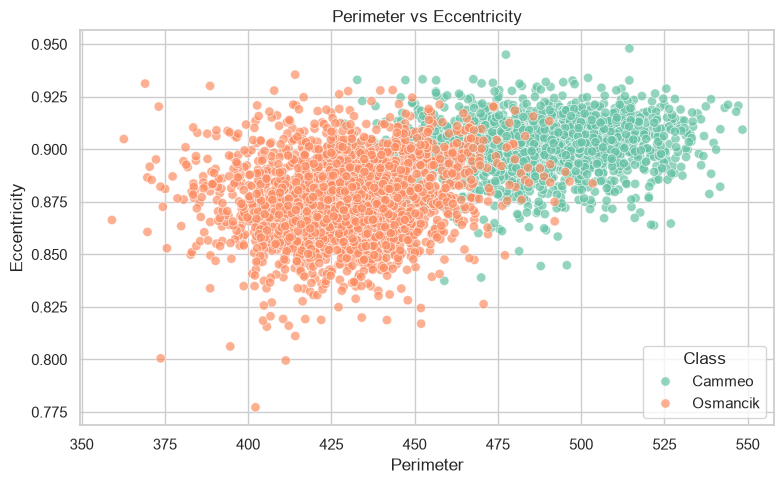

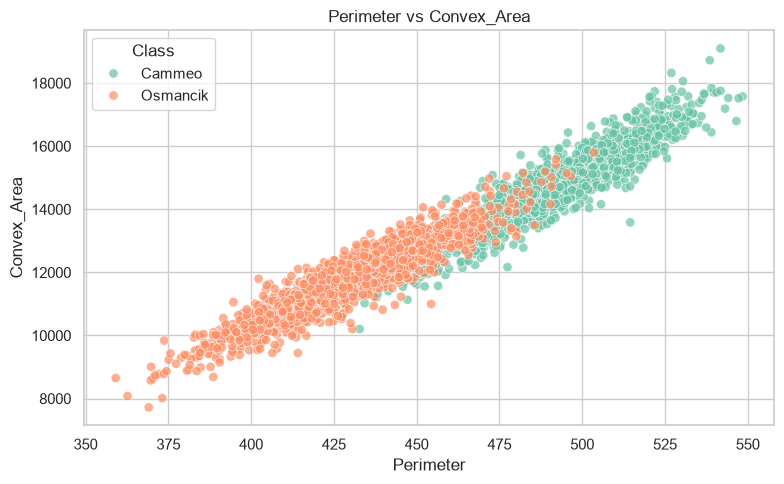

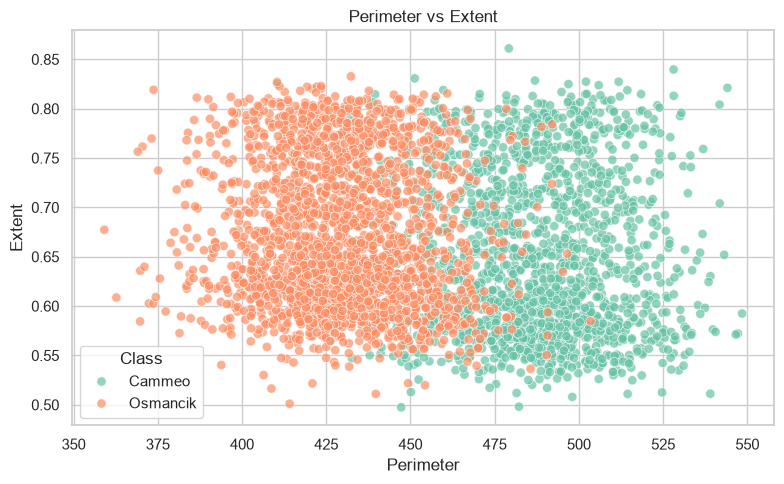

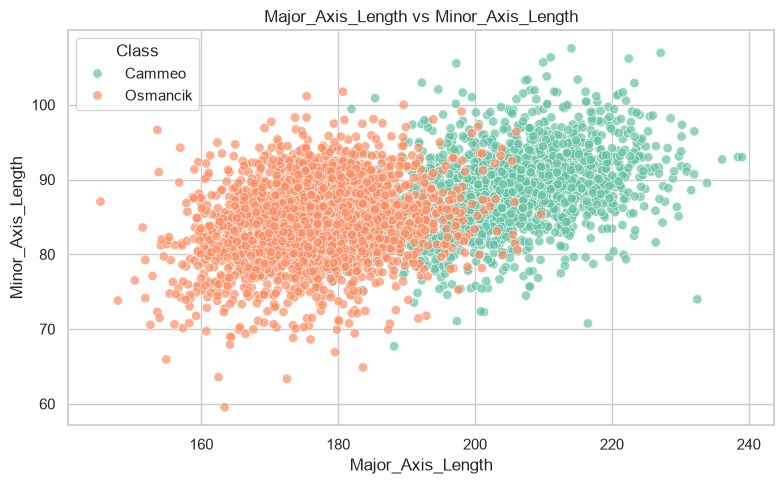

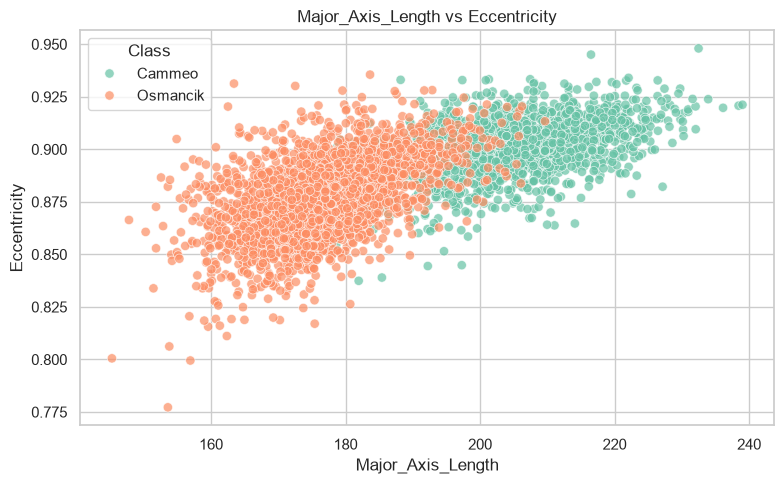

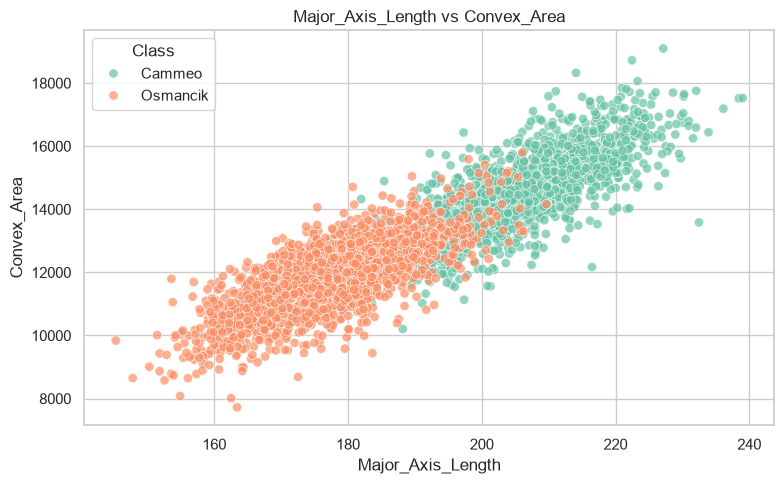

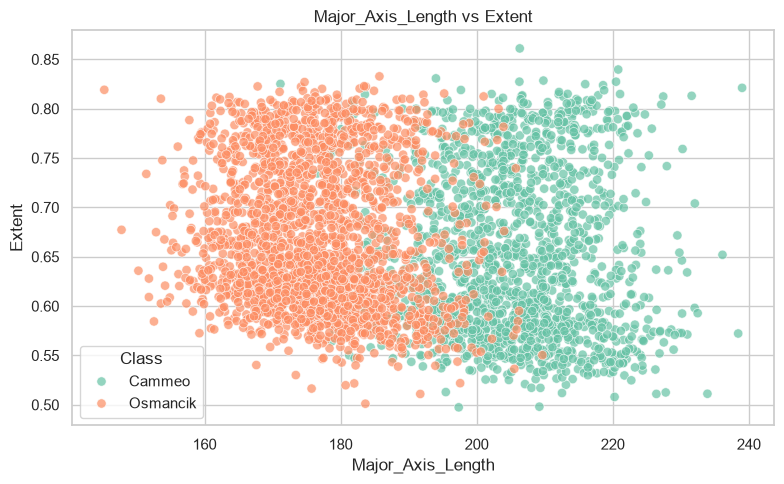

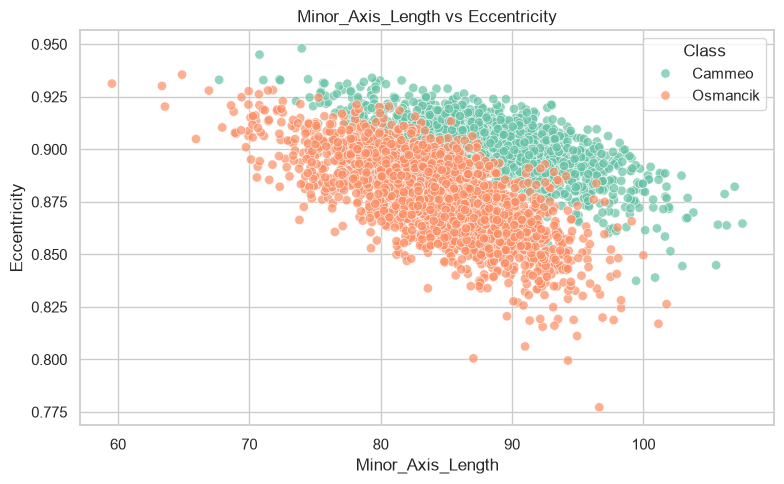

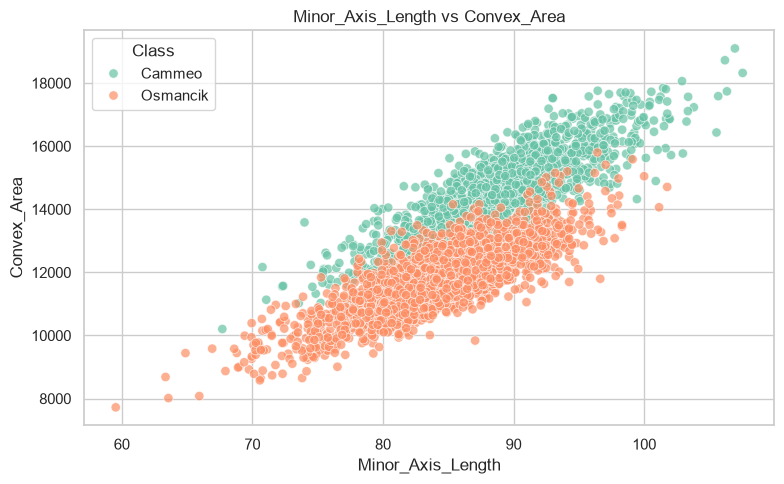

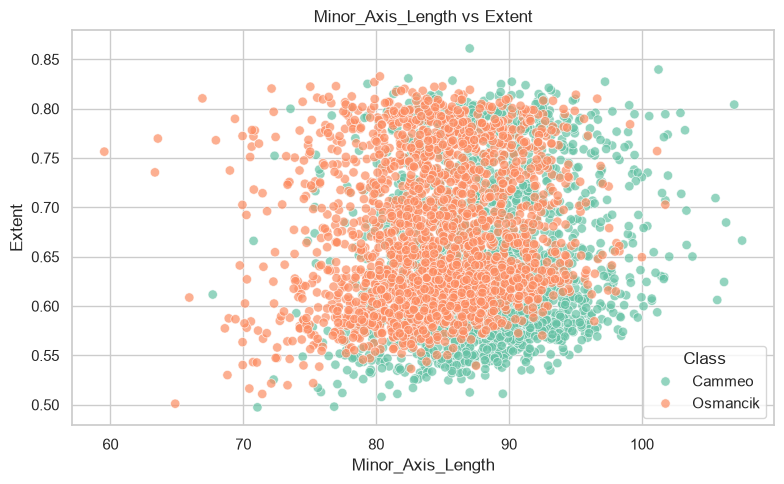

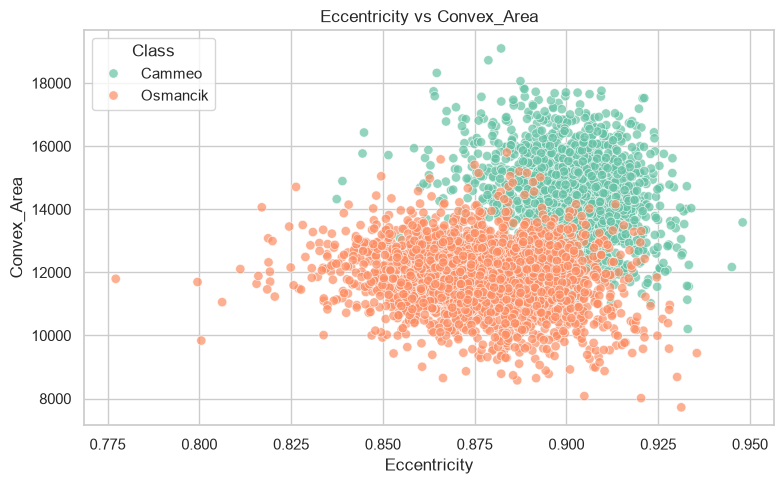

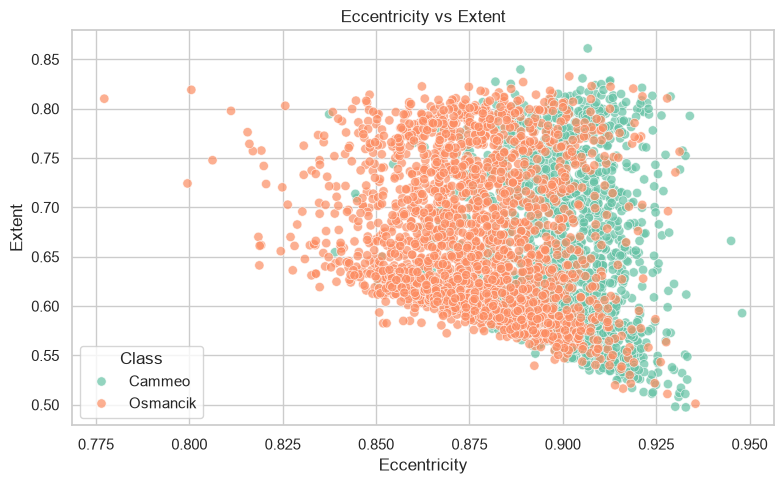

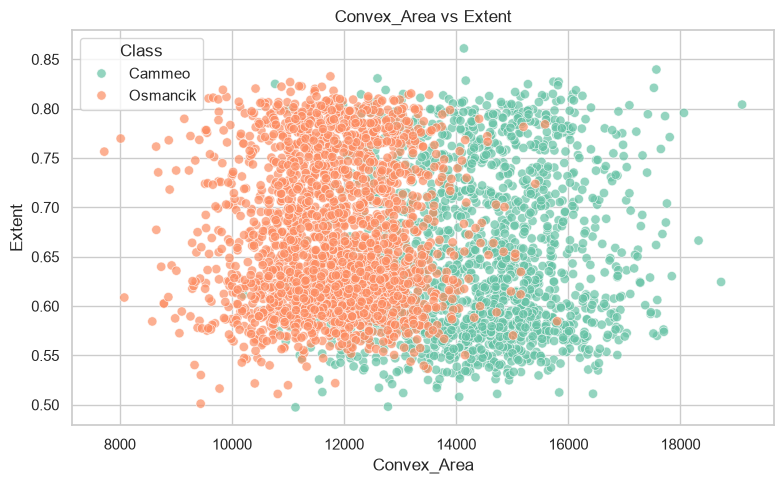

21 scatter plots made


In [28]:
pairs = list(combinations(FEATS, 2))
for a, b in pairs:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=rice, x=a, y=b, hue=TARGET, alpha=0.7, s=45)
    plt.title(f"{a} vs {b}")
    finish(f"class_separation_{a}_and_{b}")
print(len(pairs), "scatter plots made")


## 4. Distributions

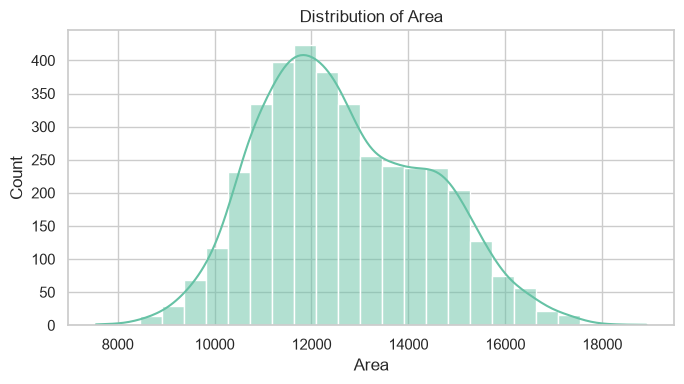

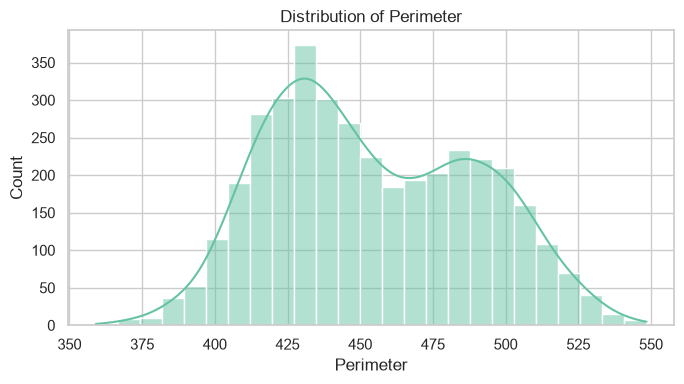

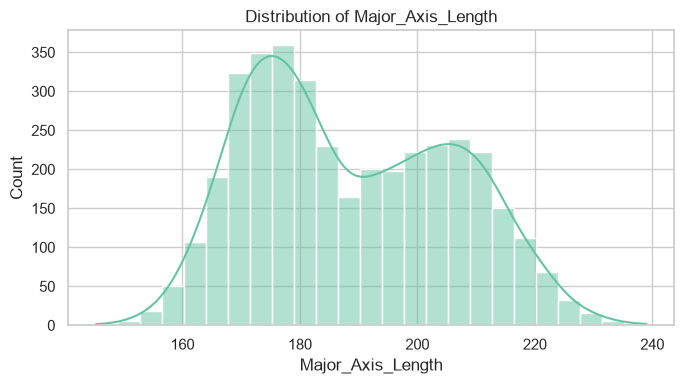

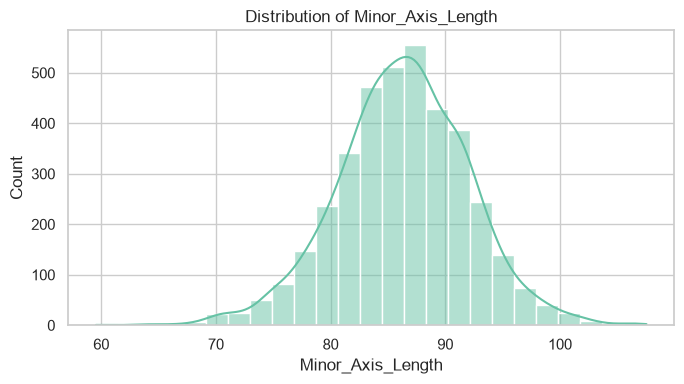

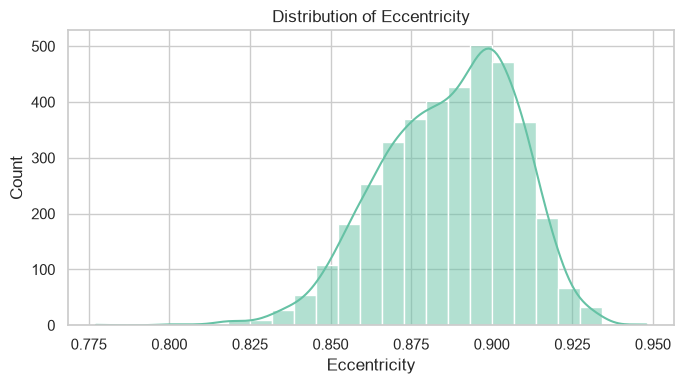

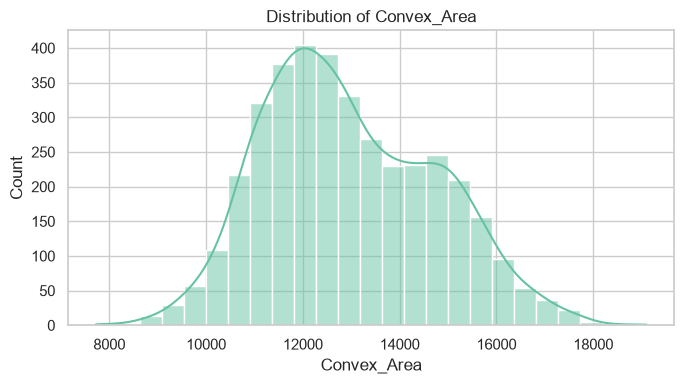

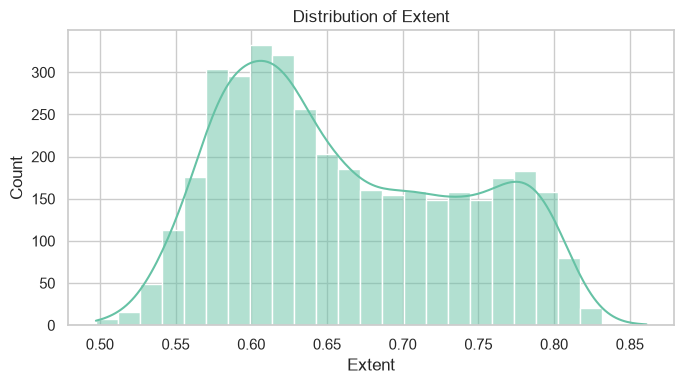

In [29]:
for f in FEATS:
    plt.figure(figsize=(7, 4))
    sns.histplot(rice[f], bins=25, kde=True)
    plt.title(f"Distribution of {f}")
    finish(f"distribution_{f}")


## 5. Outliers

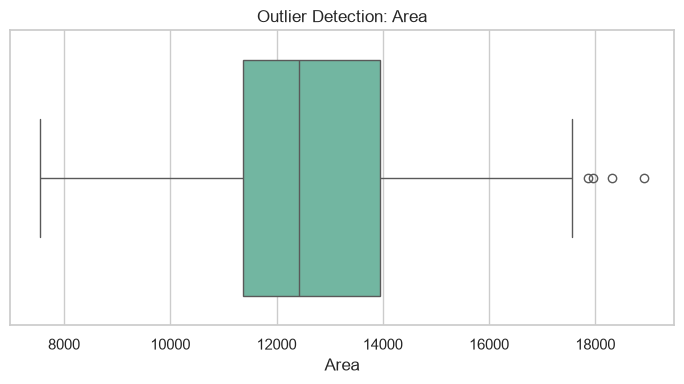

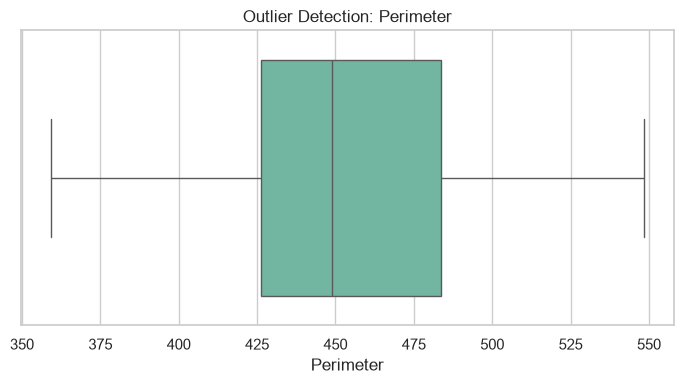

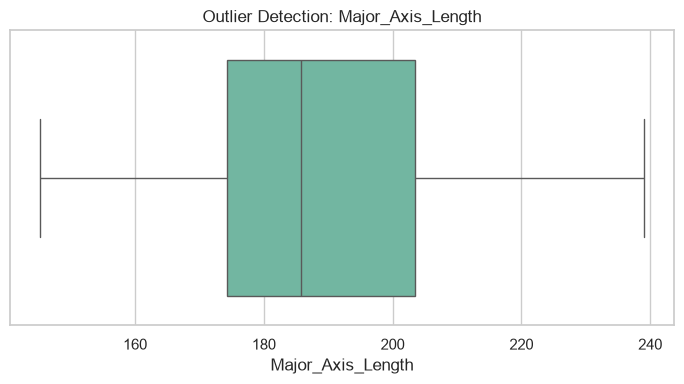

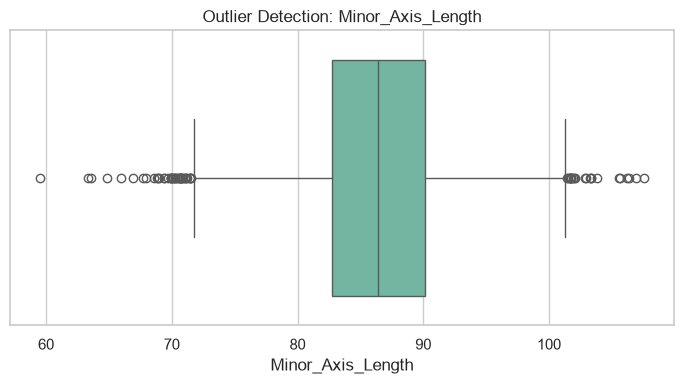

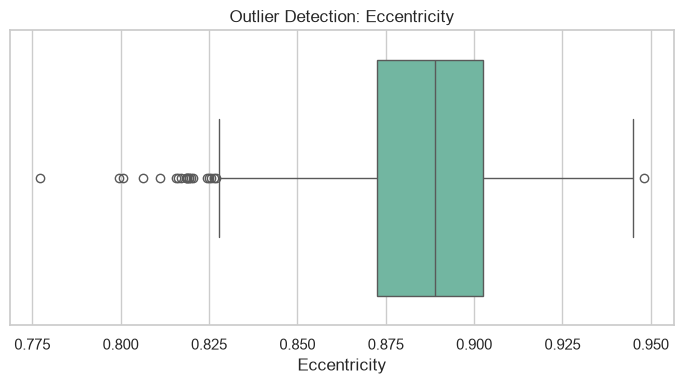

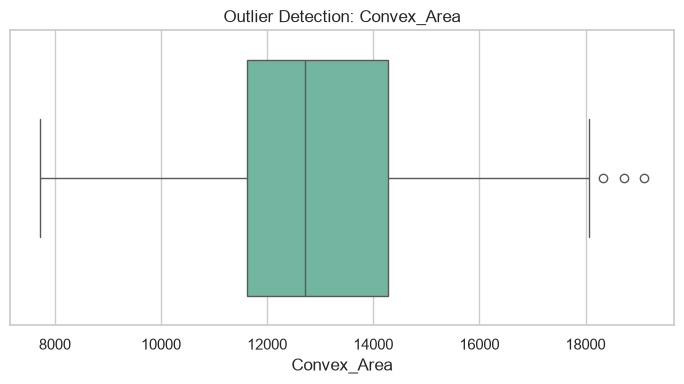

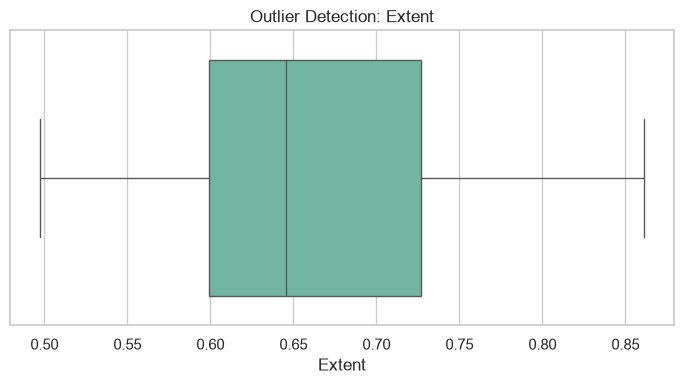

In [30]:
for f in FEATS:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x=rice[f])
    plt.title(f"Outlier Detection: {f}")
    finish(f"outliers_{f}")


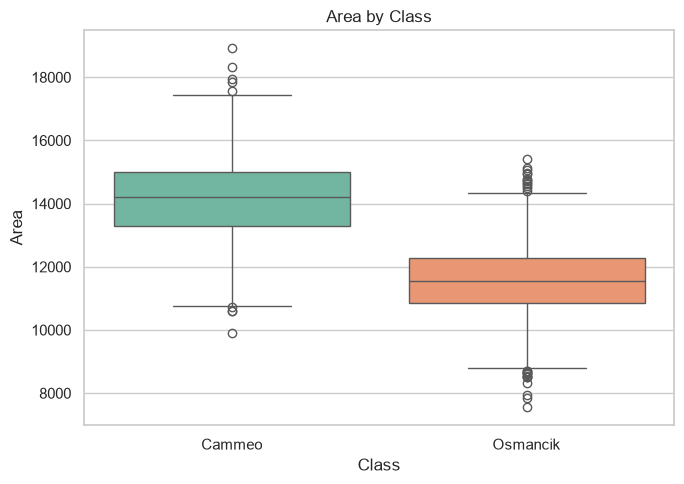

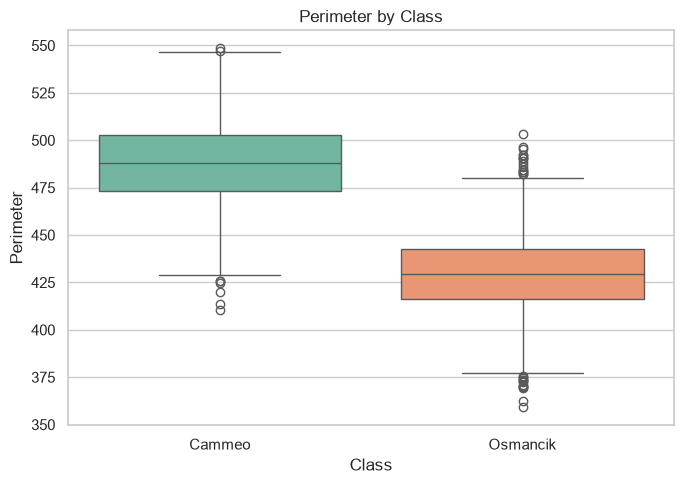

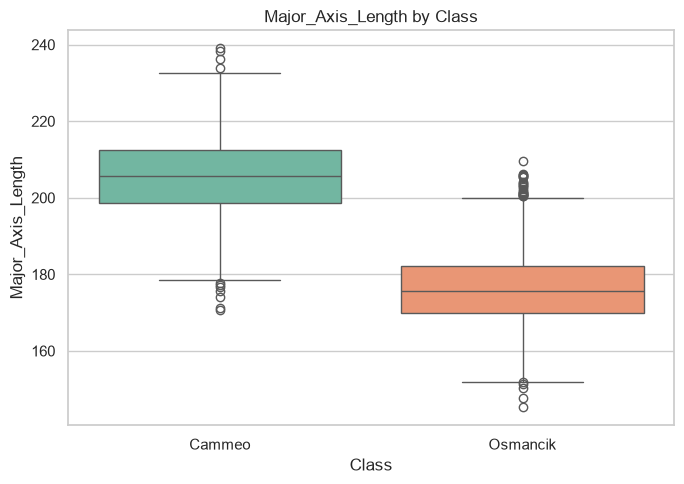

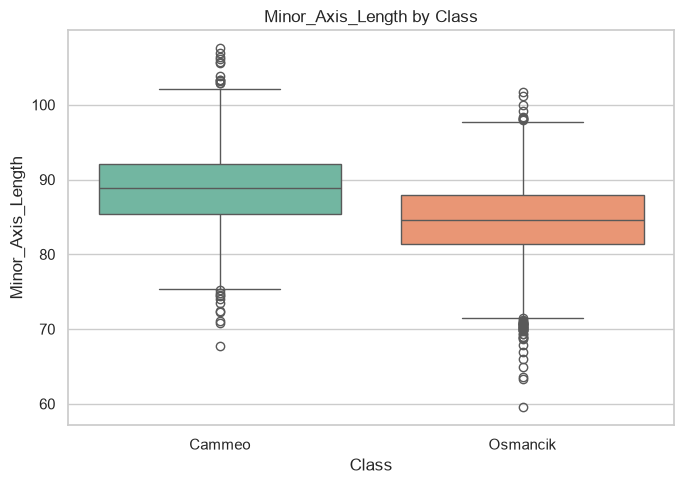

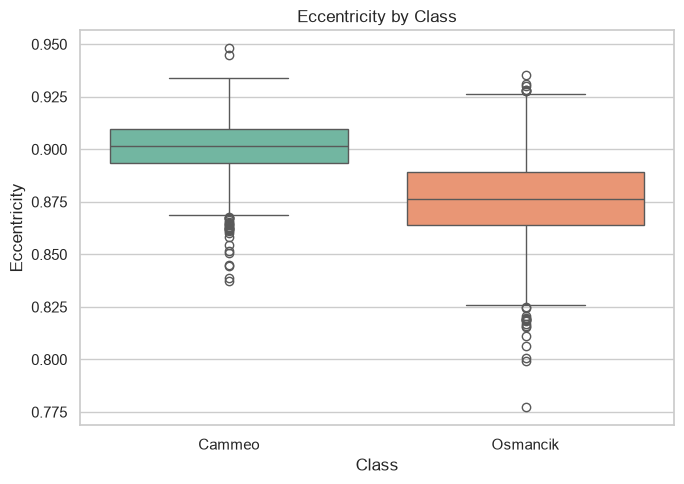

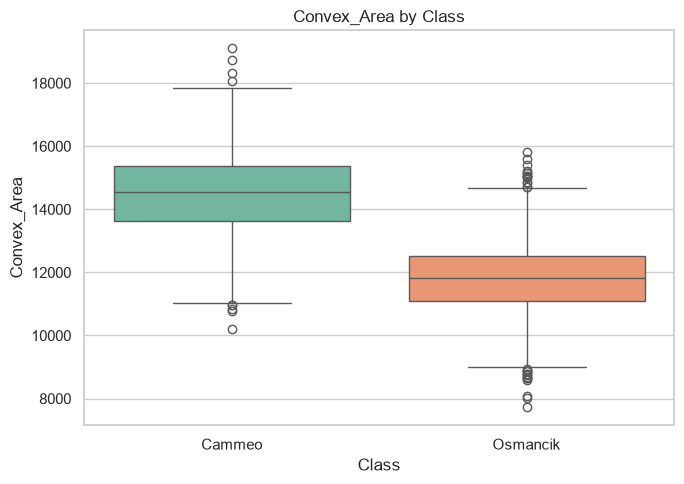

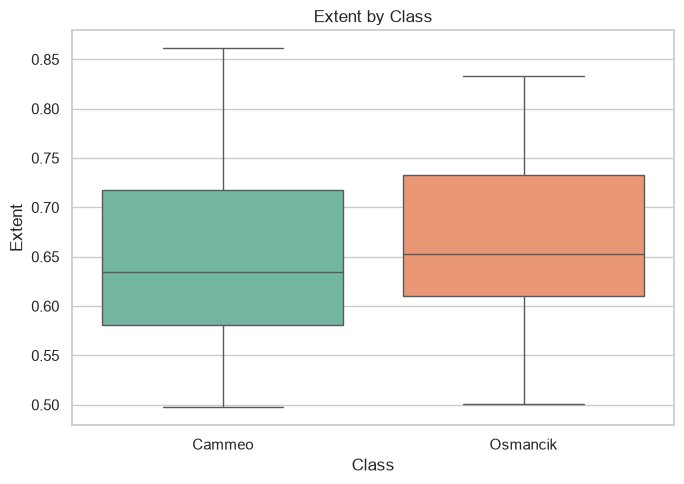

In [31]:
for f in FEATS:
    plt.figure(figsize=(7, 5))
    sns.boxplot(data=rice, x=TARGET, y=f, hue=TARGET, legend=False)
    plt.title(f"{f} by {TARGET}")
    finish(f"class_difference_{f}")


## 6. Correlations

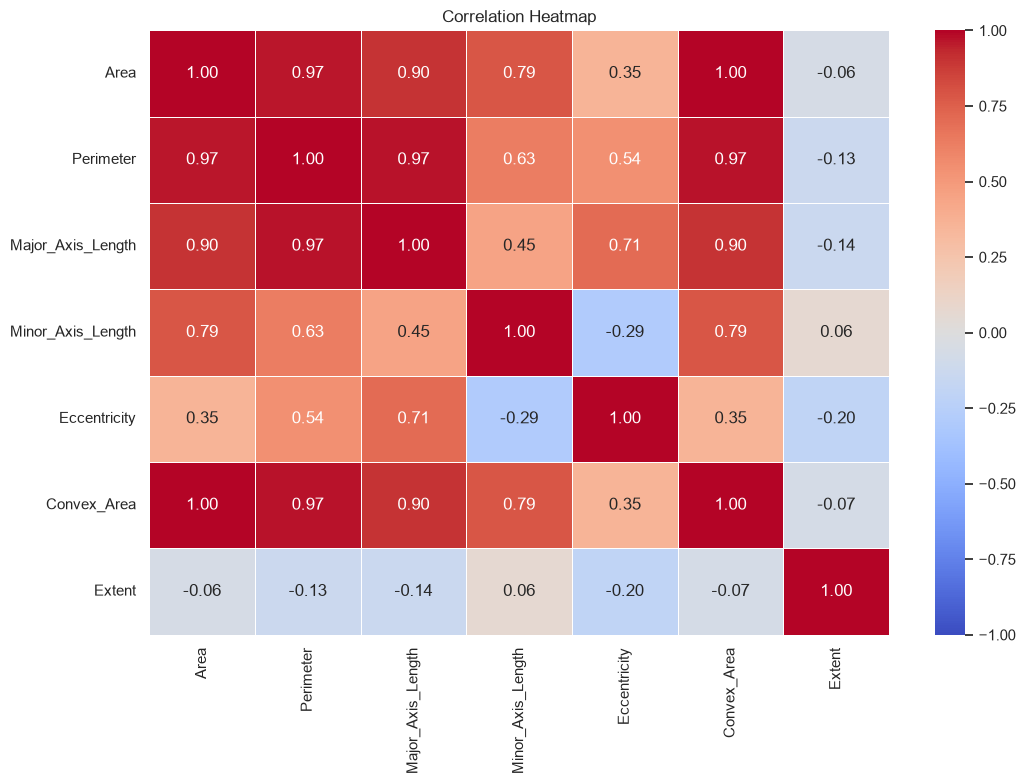

In [32]:
def heat(frame, title, name, size):
    plt.figure(figsize=size)
    sns.heatmap(frame.corr(), annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, linewidths=0.5)
    plt.title(title)
    finish(name)


heat(rice[FEATS], "Correlation Heatmap", "feature_correlations", (11, 8))


{0: 'Cammeo', 1: 'Osmancik'}


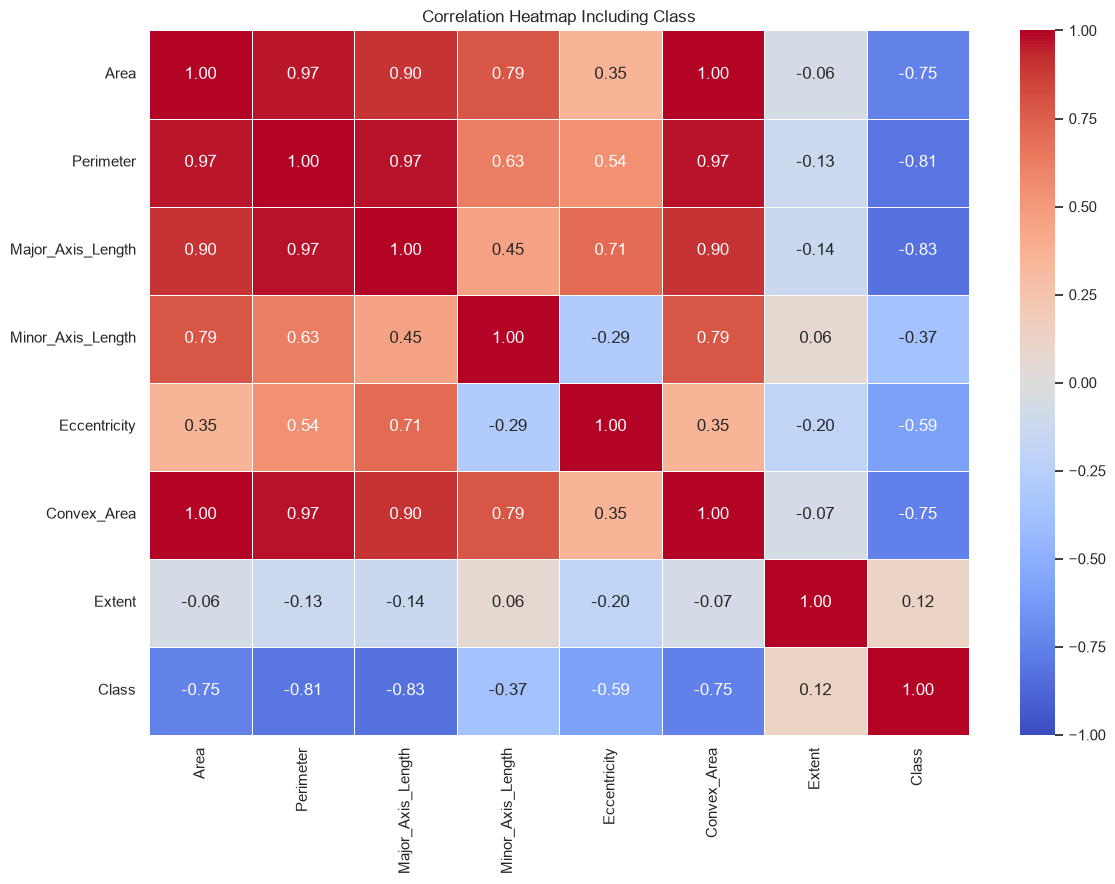

In [33]:
coded = rice[FEATS].assign(**{TARGET: rice[TARGET].astype("category").cat.codes})
print(dict(enumerate(rice[TARGET].astype("category").cat.categories)))
heat(coded, "Correlation Heatmap Including Class", "feature_class_correlations", (12, 9))


## 7. Pairplot

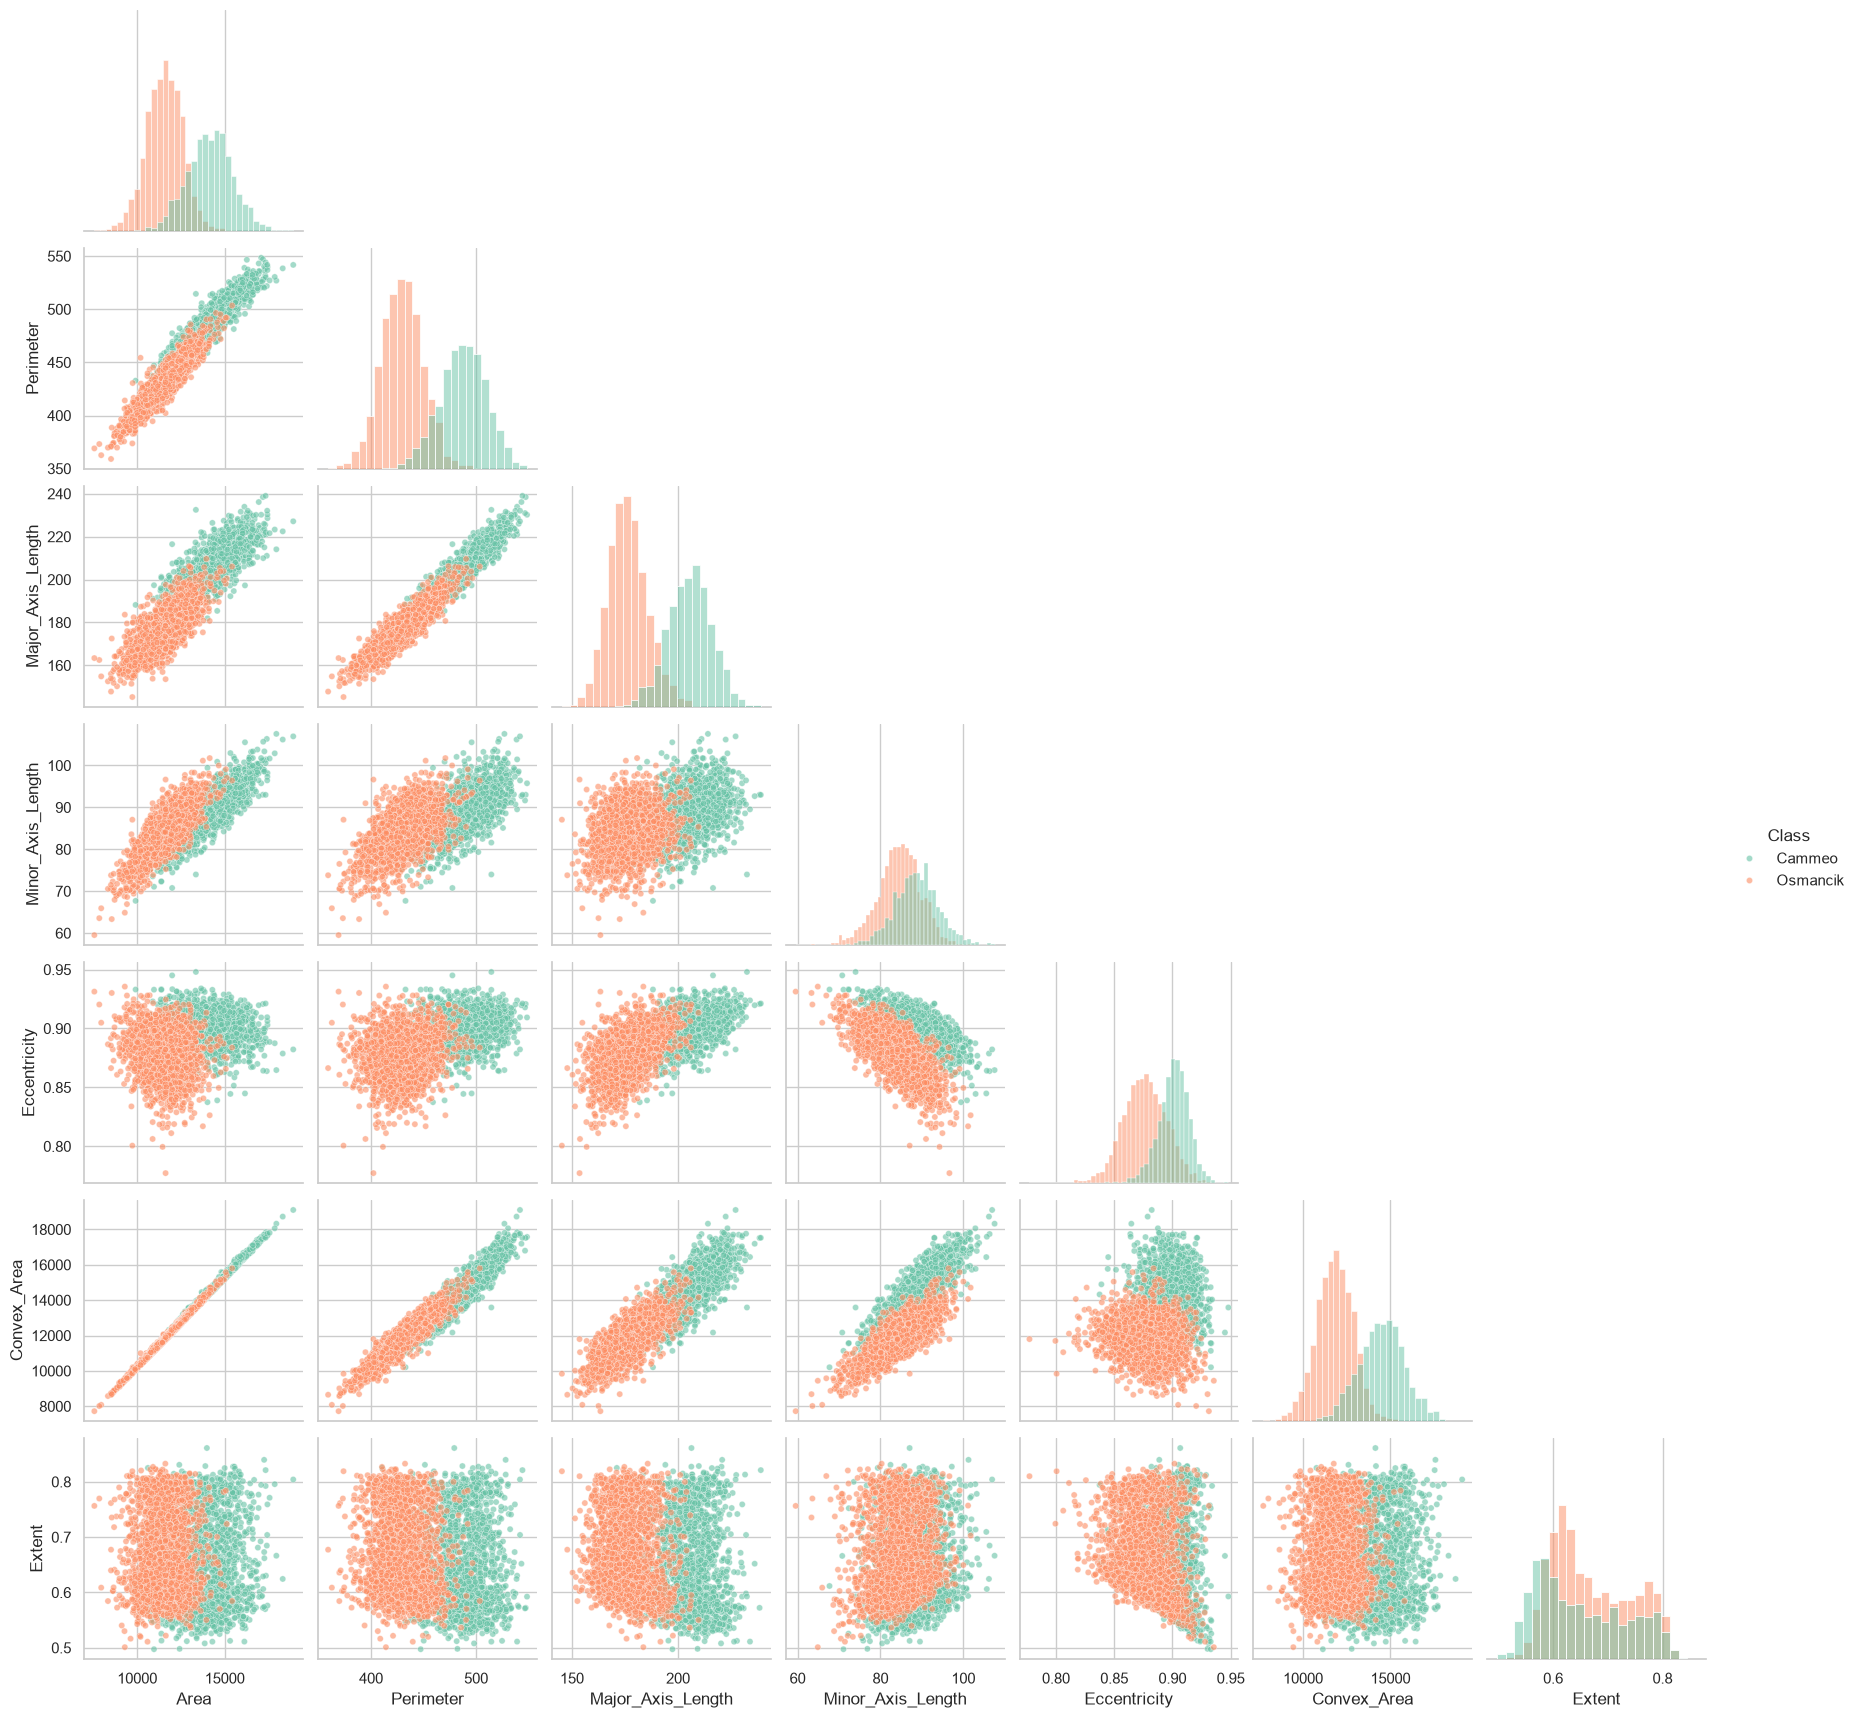

In [34]:
g = sns.pairplot(rice, vars=FEATS, hue=TARGET, diag_kind="hist", corner=True,
                 plot_kws={"alpha": 0.6, "s": 20})
g.savefig(OUT / "all_features_class_separation.png", dpi=150, bbox_inches="tight")
plt.show()


## 8. Encoding and scaling

In [35]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

y = LabelEncoder().fit_transform(rice[TARGET])
X = StandardScaler().fit_transform(rice[FEATS])

print("X:", X.shape, " y:", y.shape, " labels:", np.bincount(y))
pd.DataFrame(X, columns=FEATS).agg(["mean", "std"]).round(3)


X: (3810, 7)  y: (3810,)  labels: [1630 2180]


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent
mean,0.0,0.0,0.0,-0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 9. Linear, Ridge and Lasso regression
The 0/1 class code is the regression target; a prediction >= 0.5 is read as Osmancik.
The scaler sits inside each pipeline so it is fitted on the training rows only.

In [36]:
from sklearn.linear_model import Lasso, LassoCV, LinearRegression, Ridge, RidgeCV
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

CLASSES = rice[TARGET].astype("category").cat.categories.to_numpy()
Xtr, Xte, ytr, yte = train_test_split(rice[FEATS], y, test_size=0.2, stratify=y, random_state=42)

ridge_grid = np.logspace(-2, 4, 40)
lasso_grid = np.logspace(-5, 0, 40)


def pipe(model):
    return make_pipeline(StandardScaler(), model)


models = {
    "Linear": pipe(LinearRegression()),
    "Ridge": pipe(RidgeCV(alphas=ridge_grid)),
    "Lasso": pipe(LassoCV(alphas=lasso_grid, cv=5, max_iter=100_000, random_state=42)),
}

rows, preds, coefs = [], {}, {}
for name, m in models.items():
    m.fit(Xtr, ytr)
    p = m.predict(Xte)
    preds[name], coefs[name] = p, m[-1].coef_
    rows.append({"model": name,
                 "alpha": getattr(m[-1], "alpha_", np.nan),
                 "test R2": r2_score(yte, p),
                 "test MSE": mean_squared_error(yte, p),
                 "accuracy @0.5": accuracy_score(yte, p >= 0.5)})

results = pd.DataFrame(rows).set_index("model")
results.round(4)


,alpha,test R2,test MSE,accuracy @0.5
model,,,,
Linear,NaN,0.6668,0.0816,0.9147
Ridge,0.0289,0.6668,0.0816,0.9147
Lasso,0.0000,0.6668,0.0816,0.9147


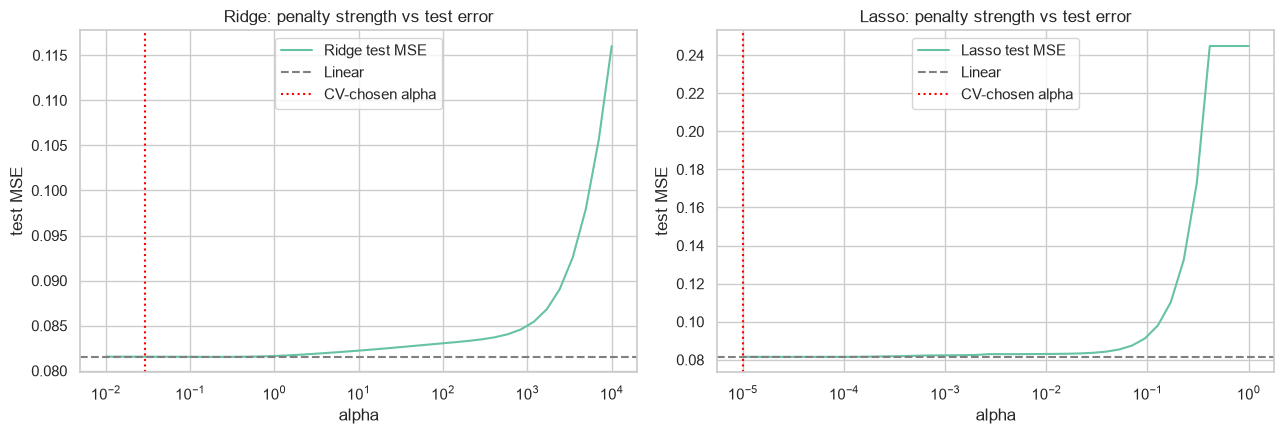

In [37]:
def sweep(make, grid):
    fits = [pipe(make(a)).fit(Xtr, ytr) for a in grid]
    mse = [mean_squared_error(yte, f.predict(Xte)) for f in fits]
    return mse, np.array([f[-1].coef_ for f in fits])


ridge_mse, ridge_path = sweep(lambda a: Ridge(alpha=a), ridge_grid)
lasso_mse, lasso_path = sweep(lambda a: Lasso(alpha=a, max_iter=100_000), lasso_grid)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, name, grid, mse in [(axes[0], "Ridge", ridge_grid, ridge_mse),
                            (axes[1], "Lasso", lasso_grid, lasso_mse)]:
    ax.semilogx(grid, mse, label=f"{name} test MSE")
    ax.axhline(results.loc["Linear", "test MSE"], ls="--", c="gray", label="Linear")
    ax.axvline(results.loc[name, "alpha"], ls=":", c="red", label="CV-chosen alpha")
    ax.set(title=f"{name}: penalty strength vs test error", xlabel="alpha", ylabel="test MSE")
    ax.legend()
finish("regularization_strength_vs_error")


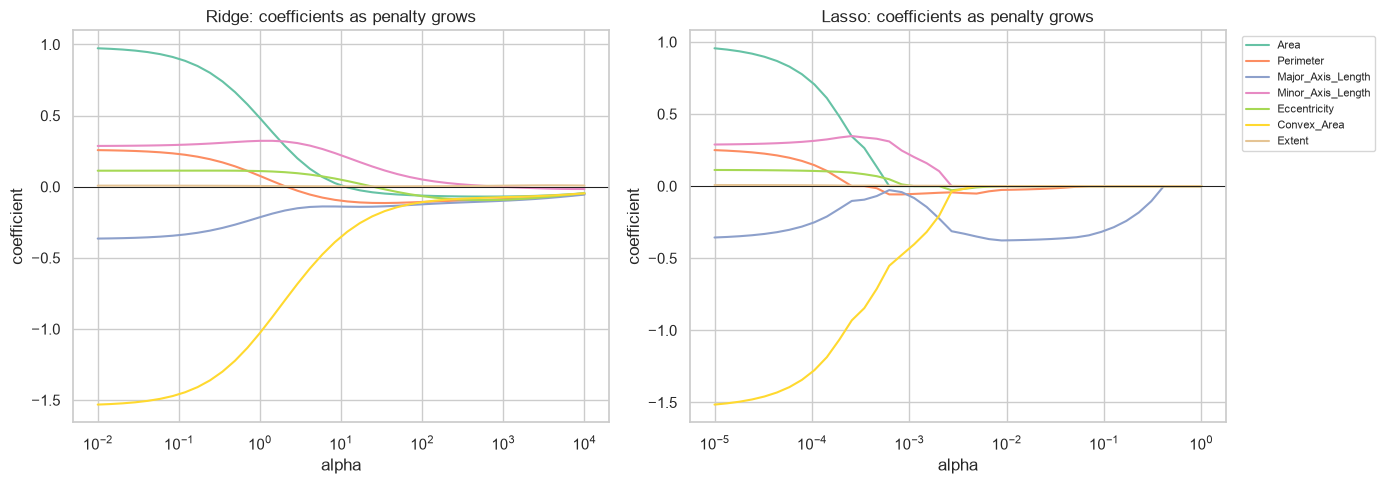

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name, grid, path in [(axes[0], "Ridge", ridge_grid, ridge_path),
                             (axes[1], "Lasso", lasso_grid, lasso_path)]:
    ax.semilogx(grid, path, label=FEATS)
    ax.axhline(0, c="k", lw=0.6)
    ax.set(title=f"{name}: coefficients as penalty grows", xlabel="alpha", ylabel="coefficient")
axes[1].legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
finish("feature_shrinkage_by_penalty")


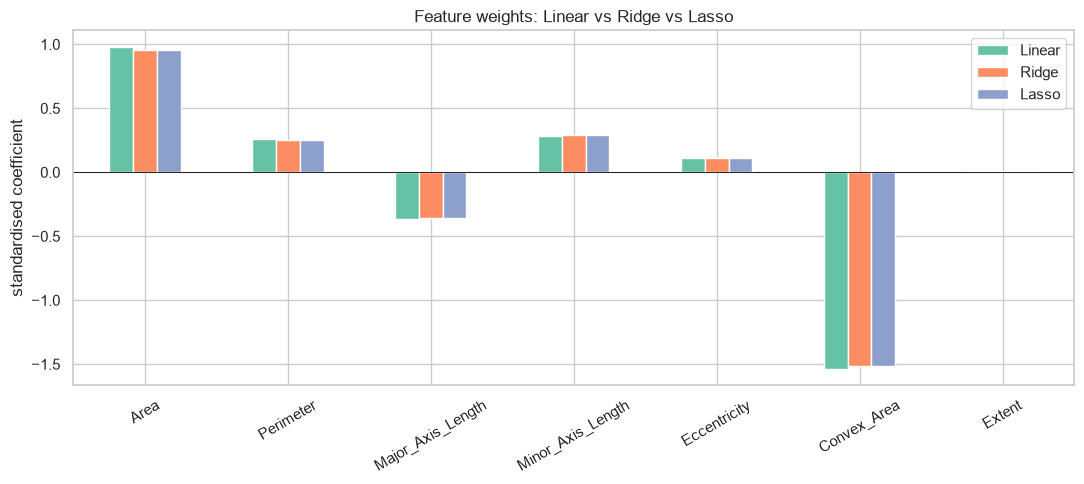

,Linear,Ridge,Lasso
Area,0.982,0.957,0.956
Perimeter,0.261,0.251,0.250
Major_Axis_Length,-0.367,-0.359,-0.356
Minor_Axis_Length,0.286,0.288,0.288
Eccentricity,0.113,0.113,0.112
Convex_Area,-1.540,-1.515,-1.515
Extent,0.008,0.008,0.008


In [39]:
coef_table = pd.DataFrame(coefs, index=FEATS)
coef_table.plot.bar(figsize=(11, 5), rot=30)
plt.axhline(0, c="k", lw=0.6)
plt.title("Feature weights: Linear vs Ridge vs Lasso")
plt.ylabel("standardised coefficient")
finish("feature_weights_by_model")
coef_table.round(3)


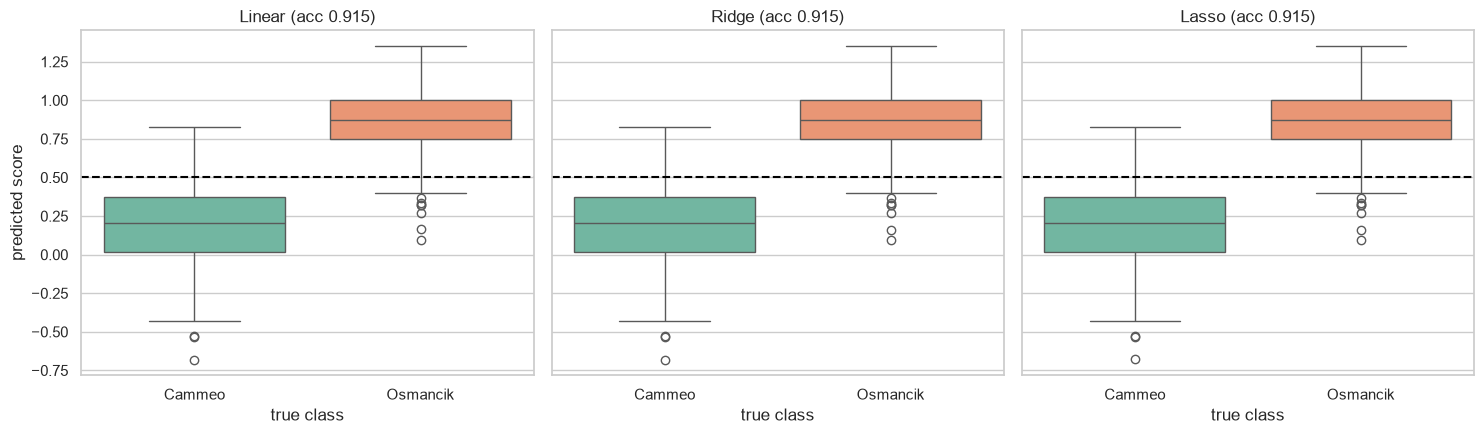

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (name, p) in zip(axes, preds.items()):
    sns.boxplot(x=CLASSES[yte], y=p, hue=CLASSES[yte], legend=False, ax=ax)
    ax.axhline(0.5, ls="--", c="k")
    ax.set(title=f"{name} (acc {results.loc[name, 'accuracy @0.5']:.3f})",
           xlabel="true class", ylabel="predicted score")
finish("class_score_separation_by_model")
